# DSCI 552 – Homework 7

**Name:** Pooja Nandyappa Subashchandra  
**GitHub Username:** nandyapp-afk  
**USC ID:** 1768721225

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import calinski_harabasz_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Relative path (forward slashes only)
DATA_PATH = "data/AnuranCalls/Frogs_MFCCs.csv"

SEED = 0
LABELS = ["Family", "Genus", "Species"]
N_FOLDS = 10
C_GRID = [0.1, 1, 10, 100, 1000]                      # SVM penalty weight (log increments)
SIGMA_GRID = [0.25, 0.5, 1, 2, 4, 8]                  # Gaussian kernel width
C_GRID_L1 = list(np.logspace(-2, 3, 6))               # penalty weight of the L1-penalized SVM
N_RUNS = 50                                           # Monte-Carlo runs in Problem 2
K_RANGE = range(2, 51)                                # candidate numbers of clusters

## Problem 1 – Multi-class and Multi-Label Classification Using SVMs

### 1(a) Load the data and choose 70% of it randomly as the training set

In [2]:
df = pd.read_csv(DATA_PATH)
X = df.filter(like="MFCCs").to_numpy()
Y = df[LABELS].to_numpy()

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=SEED, stratify=df["Species"])
print(f"Features: {X.shape[1]}   training instances: {len(X_train)}   test instances: {len(X_test)}")

Features: 22   training instances: 5036   test instances: 2159


### 1(b)i Exact match and Hamming score / loss

- **Exact match:** fraction of instances with all three labels correct.
- **Hamming loss:** fraction of wrongly predicted labels (out of 3n).
- **Hamming score:** 1 − Hamming loss.

In [3]:
def evaluate(Y_true, Y_pred):
    wrong = Y_true != Y_pred
    return {"exact match": float(np.mean(~wrong.any(axis=1))),
            "Hamming loss": float(wrong.mean()),
            "Hamming score": float(1 - wrong.mean())}


skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)


def fit_per_label(make_search, Xtr, Ytr, Xte):
    """Binary relevance: one cross-validated classifier for each label. Returns predictions and chosen parameters."""
    preds, params = [], {}
    for j, label in enumerate(LABELS):
        search = make_search().fit(Xtr, Ytr[:, j])
        preds.append(search.predict(Xte))
        params[label] = {k.split("__")[-1]: v for k, v in search.best_params_.items()}
        params[label]["CV accuracy"] = round(search.best_score_, 4)
    return np.column_stack(preds), params

### 1(b)ii Gaussian-kernel SVMs, one versus all

In [4]:
GAMMAS = [1 / (2 * s ** 2) for s in SIGMA_GRID]


def gaussian_search(standardize):
    model = OneVsRestClassifier(SVC(kernel="rbf"))
    if standardize:
        model = make_pipeline(StandardScaler(), model)
    prefix = "onevsrestclassifier__" if standardize else ""
    grid = {f"{prefix}estimator__C": C_GRID, f"{prefix}estimator__gamma": GAMMAS}
    return lambda: GridSearchCV(model, grid, cv=skf, scoring="accuracy", n_jobs=-1)


results = {}
for name, standardize in [("Gaussian SVM, raw", False), ("Gaussian SVM, standardized", True)]:
    Y_pred, params = fit_per_label(gaussian_search(standardize), X_train, Y_train, X_test)
    for p in params.values():
        p["sigma"] = round(float(np.sqrt(1 / (2 * p.pop("gamma")))), 3)
    print(name)
    display(pd.DataFrame(params).T)
    results[name] = evaluate(Y_test, Y_pred)

pd.DataFrame(results).T.round(4)

Gaussian SVM, raw


,C,CV accuracy,sigma
Family,100.0,0.9927,0.5
Genus,100.0,0.9909,0.5
Species,10.0,0.9903,0.5


Gaussian SVM, standardized


,C,CV accuracy,sigma
Family,100.0,0.9917,4.0
Genus,10.0,0.9899,4.0
Species,10.0,0.9893,4.0


,exact match,Hamming loss,Hamming score
"Gaussian SVM, raw",0.9861,0.0094,0.9906
"Gaussian SVM, standardized",0.9866,0.0100,0.9900


### 1(b)iii L1-penalized SVMs

In [5]:
def l1_search(smote):
    steps = [StandardScaler()] + ([SMOTE(random_state=SEED)] if smote else []) + \
            [LinearSVC(penalty="l1", dual=False, max_iter=20000)]
    model = make_imb_pipeline(*steps)
    return lambda: GridSearchCV(model, {"linearsvc__C": C_GRID_L1}, cv=skf, scoring="accuracy", n_jobs=-1)


Y_pred, params = fit_per_label(l1_search(smote=False), X_train, Y_train, X_test)
display(pd.DataFrame(params).T)
results["L1 SVM, standardized"] = evaluate(Y_test, Y_pred)
pd.DataFrame(results).T.round(4)

,C,CV accuracy
Family,100.0,0.9369
Genus,100.0,0.9525
Species,100.0,0.9601


,exact match,Hamming loss,Hamming score
"Gaussian SVM, raw",0.9861,0.0094,0.9906
"Gaussian SVM, standardized",0.9866,0.0100,0.9900
"L1 SVM, standardized",0.9138,0.0571,0.9429


### 1(b)iv L1-penalized SVMs with SMOTE

In [6]:
Y_pred, params = fit_per_label(l1_search(smote=True), X_train, Y_train, X_test)
display(pd.DataFrame(params).T)
results["L1 SVM, standardized + SMOTE"] = evaluate(Y_test, Y_pred)
pd.DataFrame(results).T.round(4)

,C,CV accuracy
Family,1.0,0.9180
Genus,1.0,0.9160
Species,1.0,0.9565


,exact match,Hamming loss,Hamming score
"Gaussian SVM, raw",0.9861,0.0094,0.9906
"Gaussian SVM, standardized",0.9866,0.0100,0.9900
"L1 SVM, standardized",0.9138,0.0571,0.9429
"L1 SVM, standardized + SMOTE",0.8717,0.0673,0.9327


**Conclusions:** The Gaussian-kernel SVMs perform best (exact match ≈ 0.986, Hamming loss ≈ 0.01), with raw and standardized attributes giving nearly identical results. The linear L1-penalized SVM is clearly worse (exact match 0.914), and SMOTE did not help: it lowered exact match to 0.872, since balancing the classes costs accuracy on the dominant ones.

## Problem 2 – K-Means Clustering on a Multi-Class and Multi-Label Data Set

In each of 50 runs: k ∈ {2, …, 50} is chosen by the largest Calinski-Harabasz index (undefined for k = 1); each cluster gets its majority (family, genus, species); the average Hamming distance, Hamming loss (distance/3) and Hamming score (1 − loss) are computed. Mean and standard deviation over the 50 runs are reported.

In [7]:
def one_run(seed):
    ch = {}
    labels_by_k = {}
    for k in K_RANGE:
        labels_by_k[k] = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X)
        ch[k] = calinski_harabasz_score(X, labels_by_k[k])
    k_best = max(ch, key=ch.get)
    clusters = labels_by_k[k_best]

    majority = {c: [pd.Series(Y[clusters == c, j]).mode()[0] for j in range(3)] for c in np.unique(clusters)}
    Y_assigned = np.array([majority[c] for c in clusters])
    distance = (Y != Y_assigned).sum(axis=1)
    return {"k": k_best, "Hamming distance": distance.mean(),
            "Hamming loss": distance.mean() / 3, "Hamming score": 1 - distance.mean() / 3}, ch, majority


runs = []
for seed in range(N_RUNS):
    res, ch, majority = one_run(seed)
    runs.append(res)
    if seed == 0:
        first_ch, first_majority = ch, majority

runs = pd.DataFrame(runs)
print(f"Chosen k in the {N_RUNS} runs:", runs["k"].value_counts().sort_index().to_dict())
runs.drop(columns="k").agg(["mean", "std"]).round(4)

Chosen k in the 50 runs: {2: 50}


,Hamming distance,Hamming loss,Hamming score
mean,0.8956,0.2985,0.7015
std,0.0000,0.0000,0.0000


**(a)** CH index of the first run (the chosen k has the largest value), and **(b)** the majority label triplet of every cluster in the first run:

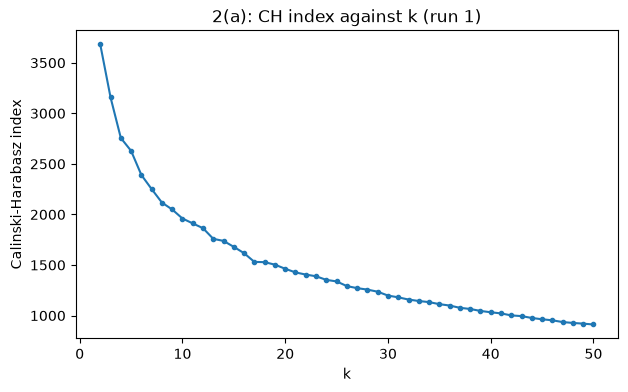

,Family,Genus,Species
cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


In [8]:
plt.figure(figsize=(7, 4))
plt.plot(list(first_ch), list(first_ch.values()), marker="o", markersize=3)
plt.xlabel("k")
plt.ylabel("Calinski-Harabasz index")
plt.title("2(a): CH index against k (run 1)")
plt.show()

pd.DataFrame(first_majority, index=LABELS).T.rename_axis("cluster")

## Problem 3 – ISLR 12.6.2

The dendrograms below are computed from the given dissimilarity matrix (heights are the fusion dissimilarities).

**(a) Complete linkage:** {1, 2} fuse at 0.3, {3, 4} fuse at 0.45, and {1, 2} and {3, 4} fuse at max(0.4, 0.7, 0.5, 0.8) = 0.8.

**(b) Single linkage:** {1, 2} fuse at 0.3, then {1, 2} and {3} fuse at min(0.4, 0.5) = 0.4, and finally {4} joins at min(0.7, 0.8, 0.45) = 0.45.

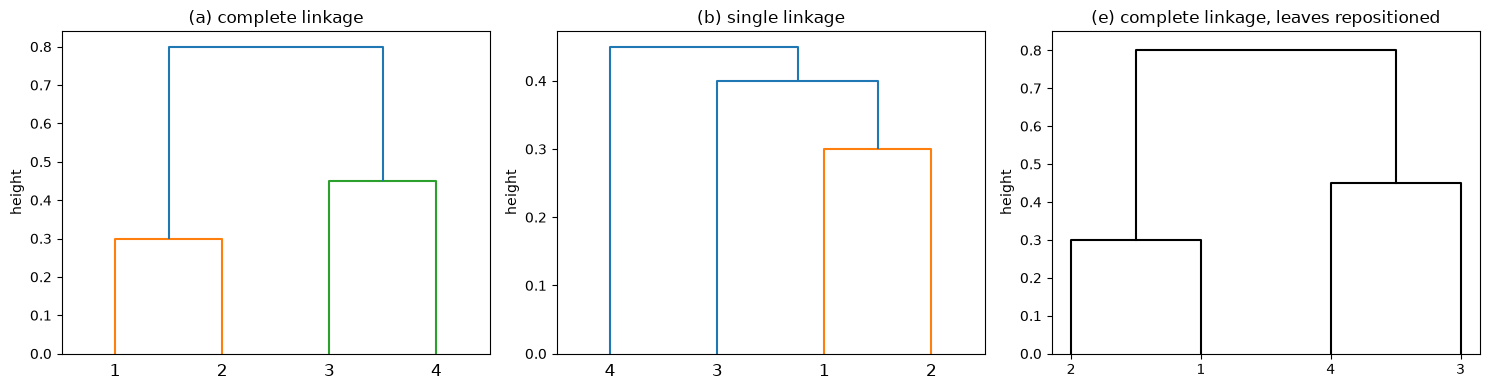

In [9]:
D = np.array([[0, 0.3, 0.4, 0.7],
              [0.3, 0, 0.5, 0.8],
              [0.4, 0.5, 0, 0.45],
              [0.7, 0.8, 0.45, 0]])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, method, title in [(axes[0], "complete", "(a) complete linkage"), (axes[1], "single", "(b) single linkage")]:
    dendrogram(linkage(squareform(D), method=method), labels=[1, 2, 3, 4], ax=ax)
    ax.set_title(title)
    ax.set_ylabel("height")

# (e): same complete-linkage dendrogram with the leaves in the order 2, 1, 4, 3
ax = axes[2]
x = {2: 0, 1: 1, 4: 2, 3: 3}
for a, b, h in [(2, 1, 0.3), (4, 3, 0.45)]:
    ax.plot([x[a], x[a], x[b], x[b]], [0, h, h, 0], "k")
ax.plot([0.5, 0.5, 2.5, 2.5], [0.3, 0.8, 0.8, 0.45], "k")
ax.set_xticks(list(x.values()))
ax.set_xticklabels(list(x.keys()))
ax.set_ylim(0, 0.85)
ax.set_title("(e) complete linkage, leaves repositioned")
ax.set_ylabel("height")
plt.tight_layout()
plt.show()

**(c)** Cutting the complete-linkage dendrogram into two clusters gives **{1, 2}** and **{3, 4}**.

**(d)** Cutting the single-linkage dendrogram into two clusters gives **{1, 2, 3}** and **{4}**.

**(e)** Swapping the leaves at each fusion, e.g. the order 2, 1, 4, 3 (right plot), gives an equivalent dendrogram: the same clusters fuse at the same heights.